# Practical 4: Multivariate Linear Regression

**Aim:** To predict house prices using multiple features such as square footage, number of bedrooms and location rating.

**Dataset:** Home Value Insights (Kaggle)

**Kaggle link:** https://www.kaggle.com/datasets/prokshitha/home-value-insights

### Dataset setup
1. Open the Kaggle link and download the dataset.
2. Extract the ZIP file.
3. Keep the CSV file in the same folder as this notebook.
4. In the next cell, use the exact CSV filename from the extracted folder. The common dataset file is `home_value_insights.csv`; if yours has a different name, change it.
5. Run cells one by one using Shift + Enter.

**Reference style:** This notebook follows your uploaded `exp4.ipynb`: `pd.read_csv()`, `df.head()`, `df.info()`, `df.describe()`, `plt.scatter()`, `df.corr()`, `sns.pairplot()`, selecting `X` and `y`, `LinearRegression()`, `fit()`, `predict()` and `score()`.

## 1. Import libraries

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

## 2. Load the dataset

In [7]:
df = pd.read_csv("house_price_regression_dataset.csv")
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Display the dataset

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


In [9]:
df.describe()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 4. Check relationships between features

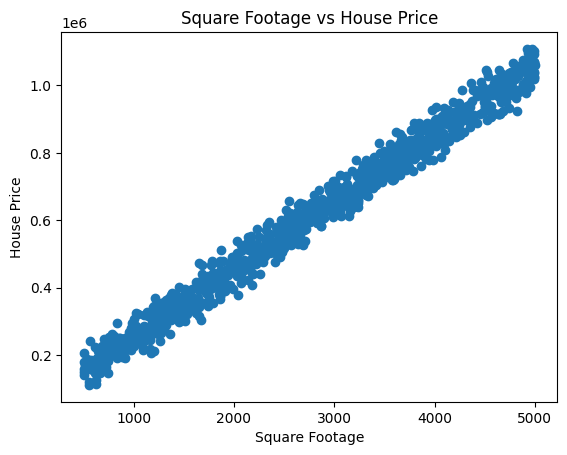

In [10]:
# Relationship between square footage and house price
plt.scatter(df["Square_Footage"], df["House_Price"])
plt.xlabel("Square Footage")
plt.ylabel("House Price")
plt.title("Square Footage vs House Price")
plt.show()

In [11]:
# Correlation between numerical columns
df.corr(numeric_only=True).style.background_gradient("Greens")

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
Square_Footage,1.000000,-0.043564,-0.031584,-0.022392,0.089479,0.030593,-0.008357,0.991261
Num_Bedrooms,-0.043564,1.000000,0.022848,-0.015820,-0.009355,0.113761,-0.049024,0.014633
Num_Bathrooms,-0.031584,0.022848,1.000000,-0.021063,0.034923,0.024846,0.017585,-0.001862
Year_Built,-0.022392,-0.015820,-0.021063,1.000000,-0.061050,-0.025485,-0.009549,0.051967
Lot_Size,0.089479,-0.009355,0.034923,-0.061050,1.000000,0.002436,0.037630,0.160412
Garage_Size,0.030593,0.113761,0.024846,-0.025485,0.002436,1.000000,-0.011287,0.052133
Neighborhood_Quality,-0.008357,-0.049024,0.017585,-0.009549,0.037630,-0.011287,1.000000,-0.007770
House_Price,0.991261,0.014633,-0.001862,0.051967,0.160412,0.052133,-0.007770,1.000000


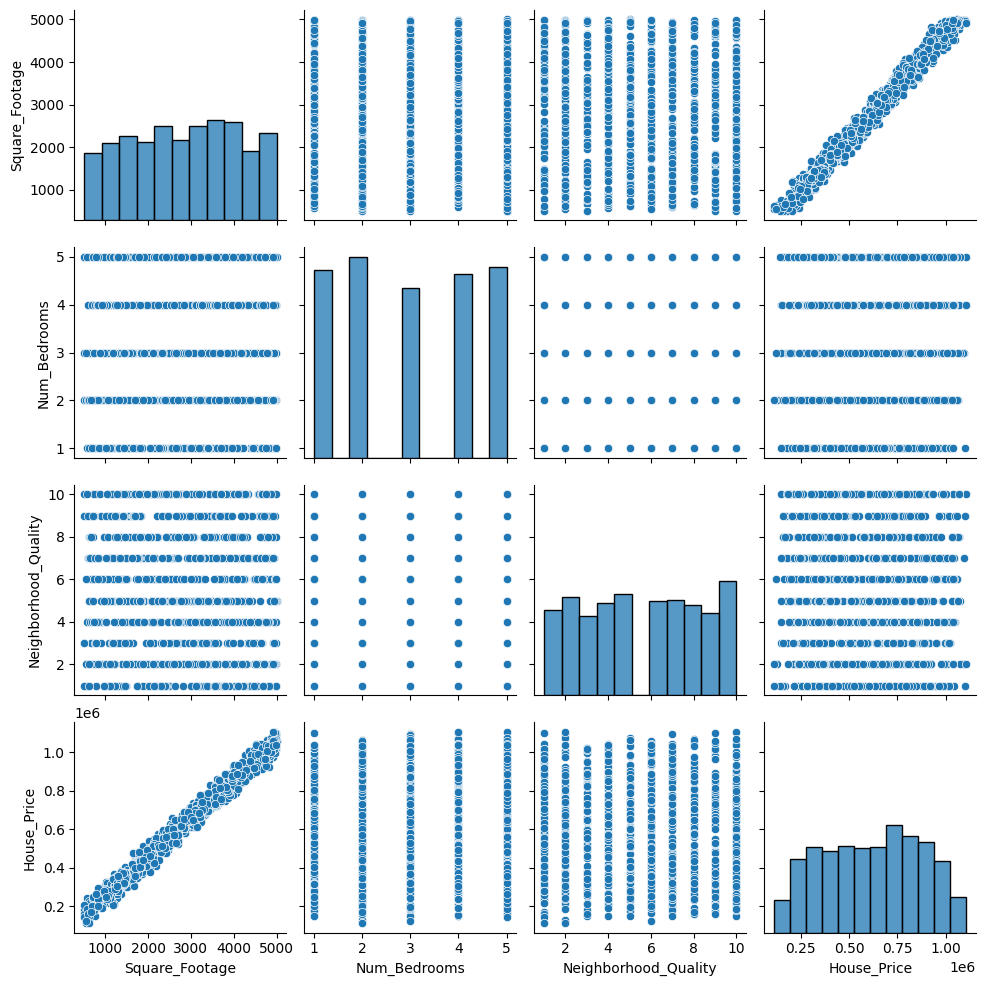

In [12]:
# Pair plot
sns.pairplot(df[["Square_Footage", "Num_Bedrooms", "Neighborhood_Quality", "House_Price"]])
plt.show()

## 5. Separate X and y

In [13]:
X = df[["Square_Footage", "Num_Bedrooms", "Neighborhood_Quality"]]
y = df["House_Price"]

X.head()

,Square_Footage,Num_Bedrooms,Neighborhood_Quality
0,1360,2,5
1,4272,3,6
2,3592,1,9
3,966,1,8
4,4926,2,8


## 6. Split the data into training and testing sets

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 800
Testing data: 200


## 7. Initialize and train the model

In [15]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

## 8. Predict house prices

In [16]:
y_pred = model.predict(X_test)

print("Predicted prices:")
print(y_pred[:5])

Predicted prices:
[ 859375.30392381  516934.77897239  979812.8054924  1032517.07677196
  766865.8341092 ]


## 9. Display accuracy and error

In [17]:
print("R2 Score:", model.score(X_test, y_test) * 100, "%")
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

R2 Score: 98.64521570014193 %
Mean Squared Error: 873278475.671967


## 10. Actual vs Predicted graph

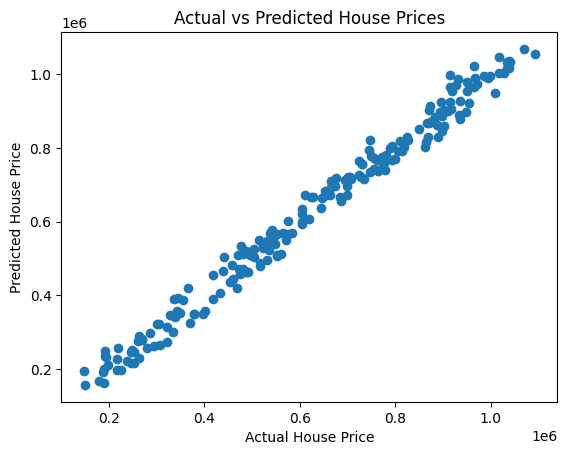

In [18]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

## 11. Predict price for a new house

In [19]:
# Square_Footage = 1500, Num_Bedrooms = 3, Neighborhood_Quality = 8
new_house = [[1500, 3, 8]]

model.predict(new_house)

/Users/aryanchavan24/JupyterProjects/jupyter-env/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([355965.34944481])

## Conclusion

Thus, Multivariate Linear Regression was implemented to predict house prices using square footage, number of bedrooms and neighborhood quality. The model was trained using `fit()` and house prices were predicted using `predict()`. Model performance was evaluated using R² score and Mean Squared Error.

## Quick revision

| Code | Purpose |
|---|---|
| `pd.read_csv()` | Load dataset |
| `df.head()` | Display first rows |
| `df.info()` | Dataset information |
| `df.describe()` | Statistical summary |
| `plt.scatter()` | Show relationship between two columns |
| `df.corr()` | Find correlation |
| `sns.pairplot()` | Show relationships between features |
| `X` | Multiple input features |
| `y` | House price output |
| `train_test_split()` | Split training and testing data |
| `LinearRegression()` | Create model |
| `model.fit()` | Train model |
| `model.predict()` | Predict house prices |
| `model.score()` | Calculate R² score |
| `mean_squared_error()` | Calculate prediction error |

**Note:** `Neighborhood_Quality` is the dataset's neighborhood-quality rating, used here as the location-rating feature.